# Predicting hotel booking cancellations

**Task:** binary classification – will a booking be cancelled (`is_canceled` = 1)?
**Data:** [Hotel Booking Demand (Kaggle)](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand) – 119,390 bookings of a city and a resort hotel in Portugal (2015–2017), based on Antonio, Almeida & Nunes (2019).
**Methods:** scikit-learn pipelines, Decision Tree, KNN, Random Forest and Gradient Boosting, baseline comparison, `GridSearchCV`, ROC-AUC, permutation importance, decision-threshold analysis.

**Key findings**
- **28.7 % of the rows are exact duplicates** (34,309). Left in, they put the same booking into both the training and the test set and inflate the scores – especially for KNN (recall of cancellations 0.65 → 0.44 after removal). The final models use the de-duplicated data (85,081 bookings).
- **`assigned_room_type` leaks the outcome** (the room is assigned at check-in, so it is unknown at booking time): bookings with a changed room are cancelled in 4.8 % of cases vs. 31.9 %. It is dropped from all models (ROC-AUC 0.844 → 0.827 without it).
- After these two corrections the **majority-class baseline is 72.1 % accuracy** and the **best model, Random Forest, reaches 80.6 % accuracy and 0.832 ROC-AUC** (precision 0.74, recall 0.48). Gradient Boosting is close (0.826); the tuned Decision Tree (0.797) and KNN (0.775) are clearly weaker.
- **Lead time, market segment and the number of special requests** are the most important predictors.
- At the default threshold the models catch fewer than half of the cancellations; lowering the threshold to 0.3 raises recall to 72 % at 56 % precision.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve)
from sklearn.inspection import permutation_importance

SEED = 42
os.makedirs("figures", exist_ok=True)

## 1. Load and select columns
We start from 21 candidate predictors. `country`, `agent`, `company`, `arrival_date_year`, `babies` and `required_car_parking_spaces` are dropped, and **`reservation_status` / `reservation_status_date` are excluded on purpose** – they are recorded after the outcome and would leak the answer. A further suspicious column, `assigned_room_type`, is examined in section 2b.

In [2]:
raw = pd.read_csv("hotel_bookings.csv")           # download from Kaggle (link above)
print("Raw shape:", raw.shape)

num_cols = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children",
            "previous_cancellations", "previous_bookings_not_canceled", "booking_changes",
            "days_in_waiting_list", "adr", "total_of_special_requests", "arrival_date_day_of_month"]
cat_cols = ["hotel", "arrival_date_month", "meal", "market_segment", "distribution_channel",
            "reserved_room_type", "assigned_room_type", "deposit_type", "customer_type"]
TARGET = "is_canceled"

df = raw[num_cols + cat_cols + [TARGET]].copy()
print("Missing values:", df.isna().sum()[df.isna().sum() > 0].to_dict())
df["children"] = df["children"].fillna(0)          # only 4 missing values

Raw shape: (119390, 32)
Missing values: {'children': 4}


## 2. Duplicates

In [3]:
dup = df.duplicated()
print(f"Exact duplicate rows: {dup.sum():,} ({dup.mean():.1%})")
df_all = df.copy()                       # with duplicates (as in the first version of the project)
df = df.drop_duplicates().reset_index(drop=True)
print("After de-duplication:", df.shape)
print("Cancellation rate:", round(df[TARGET].mean(), 3), "| majority-class accuracy:", round(1 - df[TARGET].mean(), 3))

Exact duplicate rows: 34,309 (28.7%)


After de-duplication: (85081, 22)
Cancellation rate: 0.279 | majority-class accuracy: 0.721


A duplicate is a booking identical in all 22 columns. Real bookings can coincide (e.g. a family of the same type booking the same room the same day), but 29 % is a large share, and – more importantly – identical rows on both sides of the split make the test set easier than genuinely new bookings. The effect is quantified in section 5.

## 2b. Leakage check: `assigned_room_type`
The room a guest is *assigned* is only known at check-in. If the assigned room differs from the reserved one, the guest evidently showed up – so this column can reveal the outcome and is **not available at booking time**. Let us check how strongly it helps a model.

In [4]:
changed = df["assigned_room_type"] != df["reserved_room_type"]
print(f"Assigned room differs from reserved room in {changed.mean():.1%} of bookings")
print(df.groupby(changed)[TARGET].mean().rename({False: "same room", True: "different room"}).round(3).to_string(), "\n")

def quick_auc(cats):
    Xq, yq = df[num_cols + cats], df[TARGET]
    Xtr_, Xte_, ytr_, yte_ = train_test_split(Xq, yq, test_size=0.2, random_state=SEED, stratify=yq)
    pre = ColumnTransformer([("num", StandardScaler(), num_cols), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats)])
    m = Pipeline([("prep", pre), ("clf", HistGradientBoostingClassifier(max_leaf_nodes=63, max_iter=200, random_state=SEED))]).fit(Xtr_, ytr_)
    return roc_auc_score(yte_, m.predict_proba(Xte_)[:, 1])

print("ROC-AUC with assigned_room_type   :", round(quick_auc(cat_cols), 4))
print("ROC-AUC without assigned_room_type:", round(quick_auc([c for c in cat_cols if c != "assigned_room_type"]), 4))

Assigned room differs from reserved room in 15.0% of bookings
same room         0.319
different room    0.048 



ROC-AUC with assigned_room_type   : 0.8439


ROC-AUC without assigned_room_type: 0.8272


Bookings whose room was changed are almost never cancelled, and removing the column costs a measurable amount of ROC-AUC. Because this information does not exist when a booking is made, **`assigned_room_type` is dropped from all models below** (the first version of this project kept it, which flattered the scores).

In [5]:
df = df.drop(columns="assigned_room_type"); df_all = df_all.drop(columns="assigned_room_type")
cat_cols = [c for c in cat_cols if c != "assigned_room_type"]
print("Predictors:", len(num_cols) + len(cat_cols), "(", len(num_cols), "numeric,", len(cat_cols), "categorical )")

Predictors: 20 ( 12 numeric, 8 categorical )


## 3. Exploratory data analysis

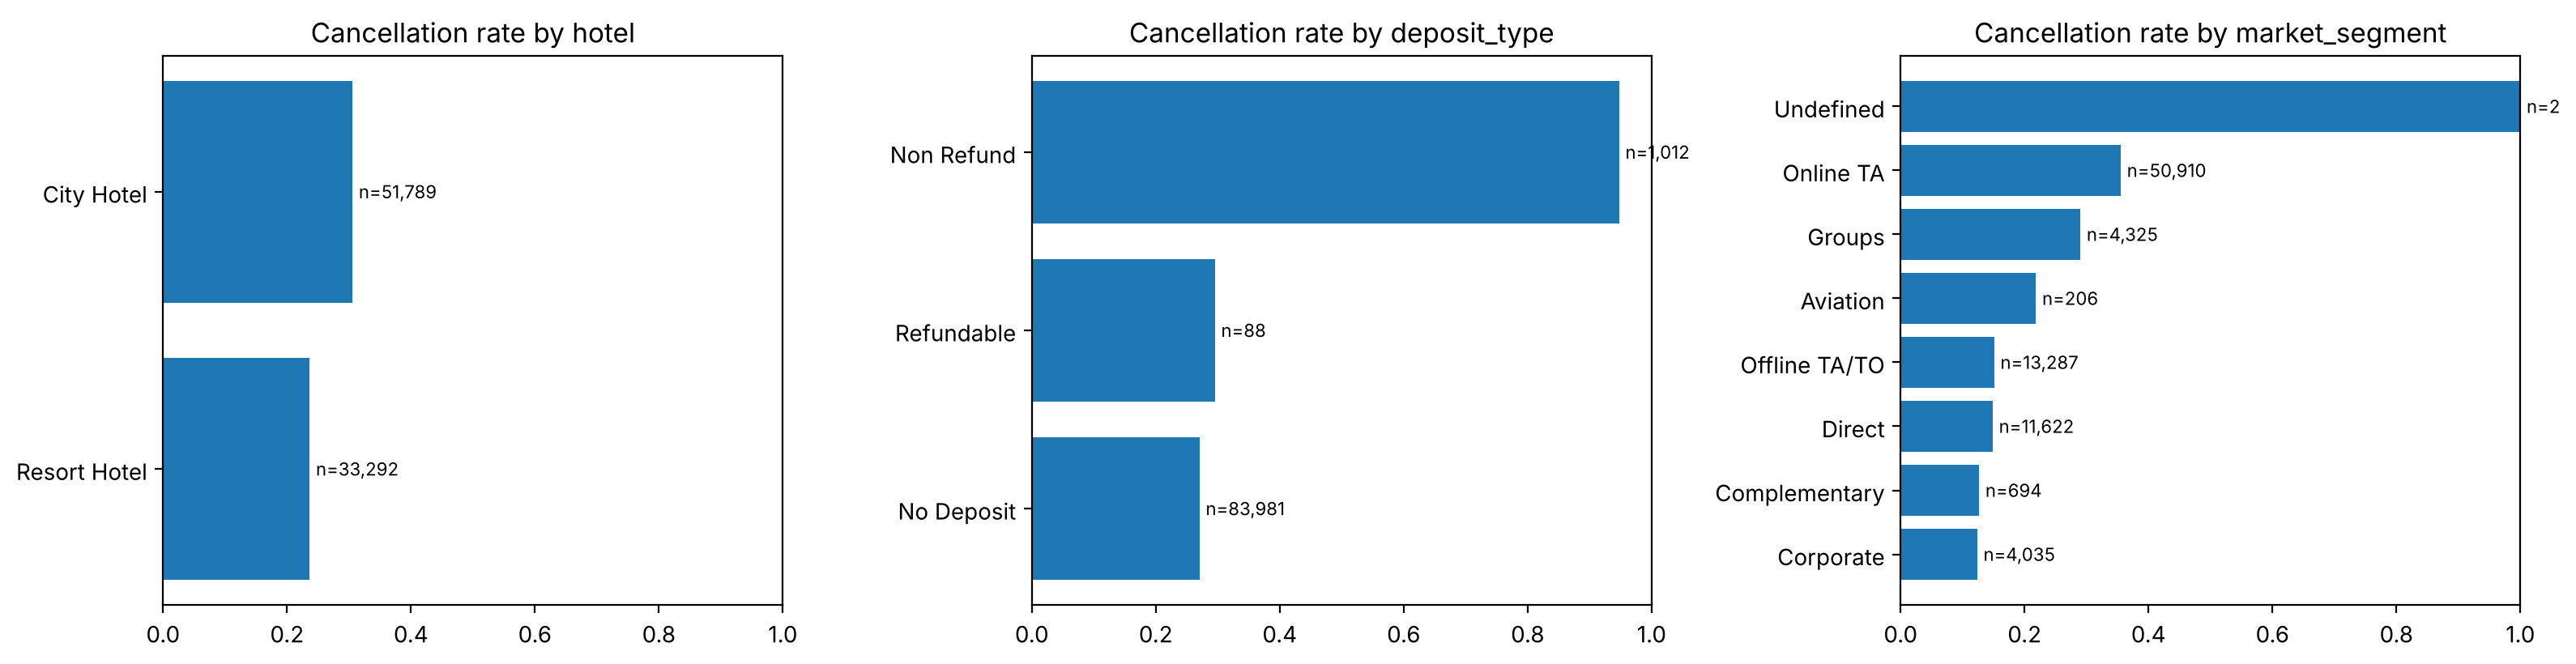

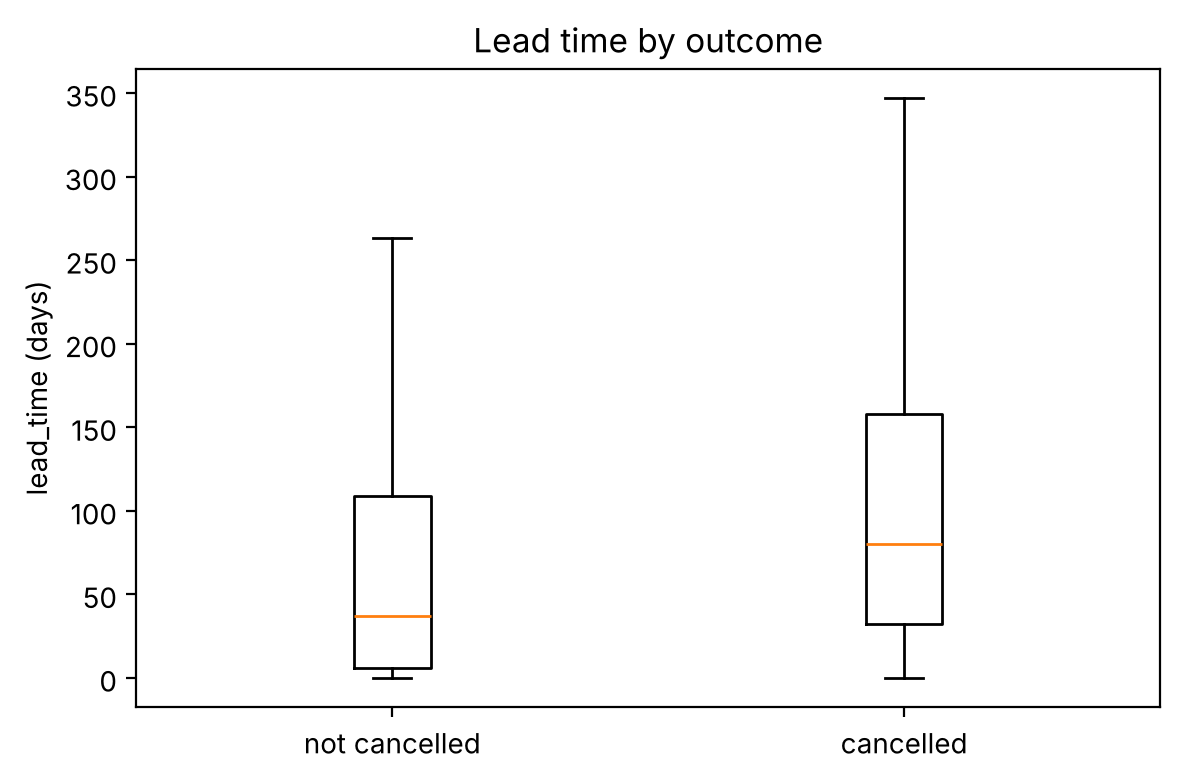

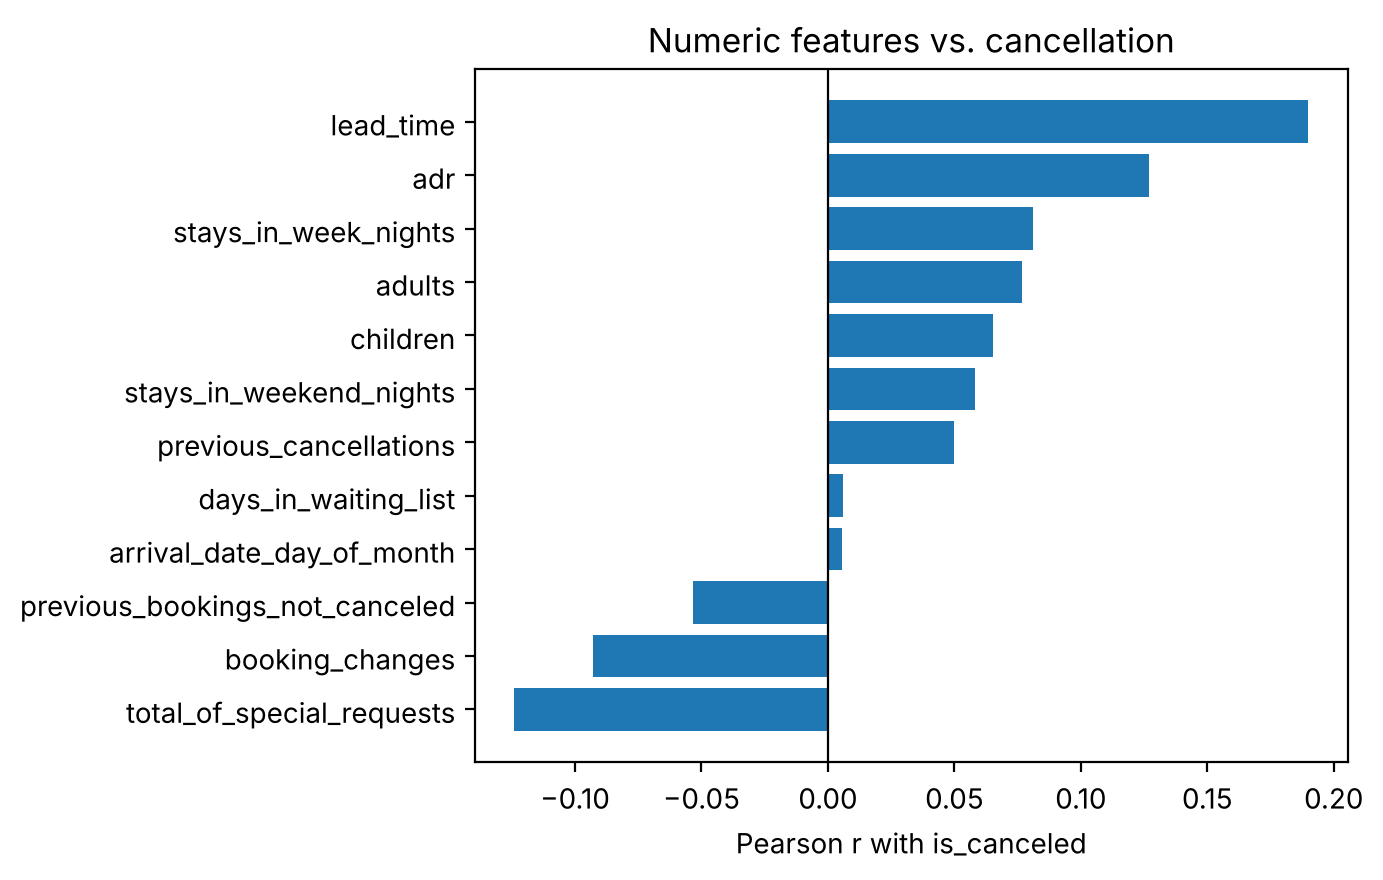

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, c in zip(axes, ["hotel", "deposit_type", "market_segment"]):
    r = df.groupby(c)[TARGET].agg(["mean", "size"]).sort_values("mean")
    ax.barh(r.index, r["mean"]); ax.set_title(f"Cancellation rate by {c}"); ax.set_xlim(0, 1)
    for y_, (m, n) in enumerate(zip(r["mean"], r["size"])): ax.text(m + .01, y_, f"n={n:,}", va="center", fontsize=8)
plt.tight_layout(); plt.savefig("figures/cancel_rate_by_category.png", dpi=200); plt.show()

plt.figure(figsize=(6, 4))
plt.boxplot([df.loc[df[TARGET] == 0, "lead_time"], df.loc[df[TARGET] == 1, "lead_time"]], showfliers=False)
plt.xticks([1, 2], ["not cancelled", "cancelled"])
plt.ylabel("lead_time (days)"); plt.title("Lead time by outcome"); plt.tight_layout()
plt.savefig("figures/lead_time_by_outcome.png", dpi=200); plt.show()

corr_t = df[num_cols + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
plt.figure(figsize=(7, 4.5)); plt.barh(corr_t.index, corr_t.values); plt.axvline(0, color="k", lw=.8)
plt.xlabel("Pearson r with is_canceled"); plt.title("Numeric features vs. cancellation"); plt.tight_layout()
plt.savefig("figures/corr_with_target.png", dpi=200); plt.show()

What the plots show (de-duplicated data, overall cancellation rate 27.9 %):
- **Deposit type:** non-refundable bookings are cancelled in 94.8 % of cases, but they are only 1,012 of 85,081 bookings (1.2 %) – a known quirk of this dataset, so the feature is predictive but rare.
- **Market segment:** online travel-agent bookings are cancelled in 35.5 % of cases, corporate bookings in 12.4 %.
- **Lead time:** the median is 80 days for cancelled and 37 days for kept bookings (strongest numeric correlation, r = 0.19).
- Bookings with a special request are cancelled less often (22.0 % vs. 33.8 %), as are bookings with changes (15.9 % vs. 30.5 %); guests with a previous cancellation cancel again in 67.4 % of cases.

## 4. Train/test split and preprocessing
80 % / 20 %, stratified. Numeric features are standardised (needed by KNN, harmless for trees), categories are one-hot encoded – both **inside the pipeline**.

In [7]:
X = df.drop(columns=[TARGET]); y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)

preprocess = ColumnTransformer([("num", StandardScaler(), num_cols),
                                ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def metrics(name, model, Xte, yte):
    pred = model.predict(Xte); proba = model.predict_proba(Xte)[:, 1]
    return {"Model": name, "Accuracy": accuracy_score(yte, pred), "Precision": precision_score(yte, pred, zero_division=0),
            "Recall": recall_score(yte, pred), "F1": f1_score(yte, pred), "ROC_AUC": roc_auc_score(yte, proba)}

Train: (68064, 20) | Test: (17017, 20)


## 5. Baselines and the effect of duplicates
The two models of the original assignment (Decision Tree with `max_depth=8`, KNN with `k=15`) are first trained on the **raw data with duplicates** and then on the **de-duplicated data**, next to a majority-class baseline.

In [8]:
def make(kind):
    clf = {"dummy": DummyClassifier(strategy="most_frequent"),
           "tree": DecisionTreeClassifier(max_depth=8, random_state=SEED),
           "knn": KNeighborsClassifier(n_neighbors=15, n_jobs=-1)}[kind]
    return Pipeline([("prep", preprocess), ("clf", clf)])

rows = []
for label, data in [("with duplicates", df_all), ("de-duplicated", df)]:
    Xa, ya = data.drop(columns=[TARGET]), data[TARGET]
    Xtr, Xte, ytr, yte = train_test_split(Xa, ya, test_size=0.2, random_state=SEED, stratify=ya)
    for kind, nm in [("dummy", "Majority baseline"), ("tree", "Decision Tree (depth 8)"), ("knn", "KNN (k=15)")]:
        m = make(kind).fit(Xtr, ytr)
        r = metrics(nm, m, Xte, yte); r["Data"] = label; rows.append(r)
baseline = pd.DataFrame(rows)[["Data", "Model", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]].round(3)
baseline

,Data,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,with duplicates,Majority baseline,0.630,0.000,0.000,0.000,0.500
1,with duplicates,Decision Tree (depth 8),0.810,0.838,0.605,0.703,0.859
2,with duplicates,KNN (k=15),0.813,0.807,0.650,0.720,0.867
3,de-duplicated,Majority baseline,0.721,0.000,0.000,0.000,0.500
4,de-duplicated,Decision Tree (depth 8),0.791,0.682,0.466,0.554,0.788
5,de-duplicated,KNN (k=15),0.780,0.658,0.442,0.529,0.769


**Removing the duplicates changes the picture considerably** (note that the majority baseline itself rises from 0.630 to 0.721 because the duplicated rows are cancelled much more often – the overall cancellation rate falls from 37.0 % to 27.9 %):

| | accuracy (with duplicates → without) | recall of cancellations | ROC-AUC |
|---|---|---|---|
| Decision Tree (depth 8) | 0.810 → 0.791 | 0.605 → 0.466 | 0.859 → 0.788 |
| KNN (k=15) | 0.813 → 0.780 | 0.650 → 0.442 | 0.867 → 0.769 |

The gain over the majority baseline shrinks from about 18 to about 6–7 percentage points. The test set no longer contains bookings the model has already seen in training, so the numbers are a more honest estimate for genuinely new bookings. **All following results use the de-duplicated data.**

## 6. Hyper-parameter tuning and additional models
Tuning with `GridSearchCV` (5-fold, scoring = ROC-AUC) **on the training set only**. KNN is tuned on a 15,000-row subsample for speed. Random Forest and Gradient Boosting are added as stronger reference models (they were listed as "future work" in the original assignment).

In [9]:
tree_grid = GridSearchCV(Pipeline([("prep", preprocess), ("clf", DecisionTreeClassifier(random_state=SEED))]),
    {"clf__max_depth": [4, 6, 8, 10, 12, 16, None], "clf__min_samples_leaf": [1, 10, 50]},
    cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
print("Decision Tree:", tree_grid.best_params_, "| CV ROC-AUC =", round(tree_grid.best_score_, 4))

sub = X_train.sample(15000, random_state=SEED); ysub = y_train.loc[sub.index]
knn_grid = GridSearchCV(Pipeline([("prep", preprocess), ("clf", KNeighborsClassifier(n_jobs=-1))]),
    {"clf__n_neighbors": [5, 15, 31, 61, 101], "clf__weights": ["uniform", "distance"]},
    cv=cv, scoring="roc_auc").fit(sub, ysub)
print("KNN (on subsample):", knn_grid.best_params_, "| CV ROC-AUC =", round(knn_grid.best_score_, 4))

hgb_grid = GridSearchCV(Pipeline([("prep", preprocess), ("clf", HistGradientBoostingClassifier(random_state=SEED))]),
    {"clf__learning_rate": [0.05, 0.1], "clf__max_leaf_nodes": [15, 31, 63], "clf__max_iter": [200]},
    cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
print("Gradient Boosting:", hgb_grid.best_params_, "| CV ROC-AUC =", round(hgb_grid.best_score_, 4))

Decision Tree: {'clf__max_depth': 12, 'clf__min_samples_leaf': 50} | CV ROC-AUC = 0.7939


KNN (on subsample): {'clf__n_neighbors': 101, 'clf__weights': 'distance'} | CV ROC-AUC = 0.7594


Gradient Boosting: {'clf__learning_rate': 0.05, 'clf__max_iter': 200, 'clf__max_leaf_nodes': 63} | CV ROC-AUC = 0.8234


## 7. Final evaluation on the held-out test set

In [10]:
knn_final = Pipeline([("prep", preprocess), ("clf", KNeighborsClassifier(n_jobs=-1, **{k.split("__")[1]: v for k, v in knn_grid.best_params_.items()}))]).fit(X_train, y_train)
rf = Pipeline([("prep", preprocess), ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1))]).fit(X_train, y_train)
base = make("dummy").fit(X_train, y_train)

final = {"Majority baseline": base, "Decision Tree (tuned)": tree_grid.best_estimator_, "KNN (tuned)": knn_final,
         "Random Forest": rf, "Gradient Boosting (tuned)": hgb_grid.best_estimator_}
results = pd.DataFrame([metrics(n, m, X_test, y_test) for n, m in final.items()]).round(3)
results

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Majority baseline,0.721,0.000,0.000,0.000,0.500
1,Decision Tree (tuned),0.791,0.695,0.448,0.545,0.797
2,KNN (tuned),0.782,0.688,0.396,0.503,0.775
3,Random Forest,0.806,0.735,0.475,0.577,0.832
4,Gradient Boosting (tuned),0.803,0.715,0.487,0.579,0.826


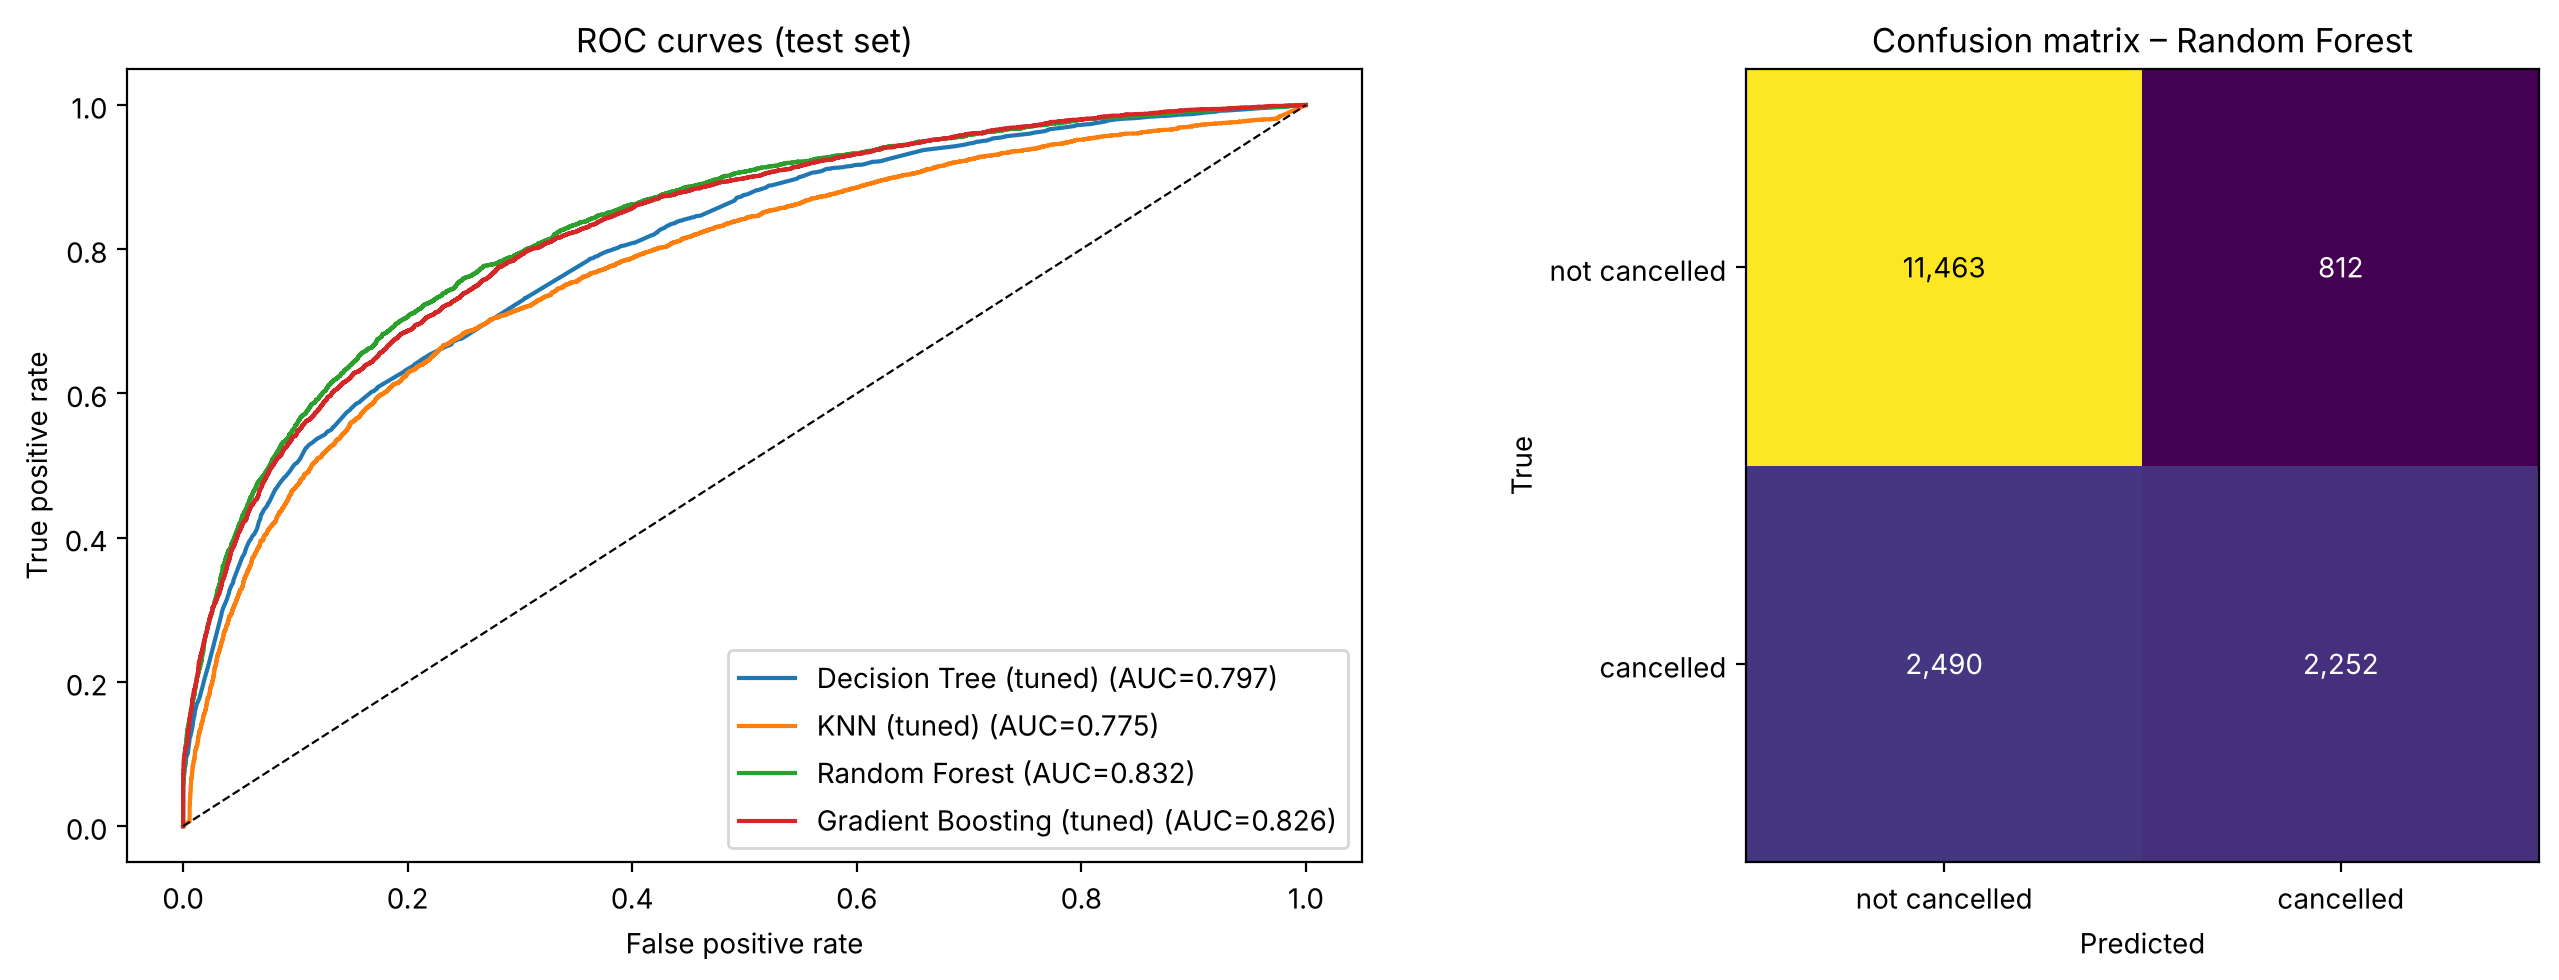

Best model by ROC-AUC: Random Forest


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for n, m in final.items():
    if n == "Majority baseline": continue
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    axes[0].plot(fpr, tpr, label=f"{n} (AUC={roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=.8); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves (test set)"); axes[0].legend(loc="lower right")

best_name = results.iloc[1:].sort_values("ROC_AUC", ascending=False).iloc[0]["Model"]
cm = confusion_matrix(y_test, final[best_name].predict(X_test))
axes[1].imshow(cm); axes[1].set_title(f"Confusion matrix – {best_name}")
axes[1].set_xticks([0, 1], ["not cancelled", "cancelled"]); axes[1].set_yticks([0, 1], ["not cancelled", "cancelled"])
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("True")
for i in range(2):
    for j in range(2): axes[1].text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="white" if cm[i, j] < cm.max()/2 else "black")
plt.tight_layout(); plt.savefig("figures/roc_and_confusion.png", dpi=200); plt.show()
print("Best model by ROC-AUC:", best_name)

## 8. What drives cancellations? (permutation importance)

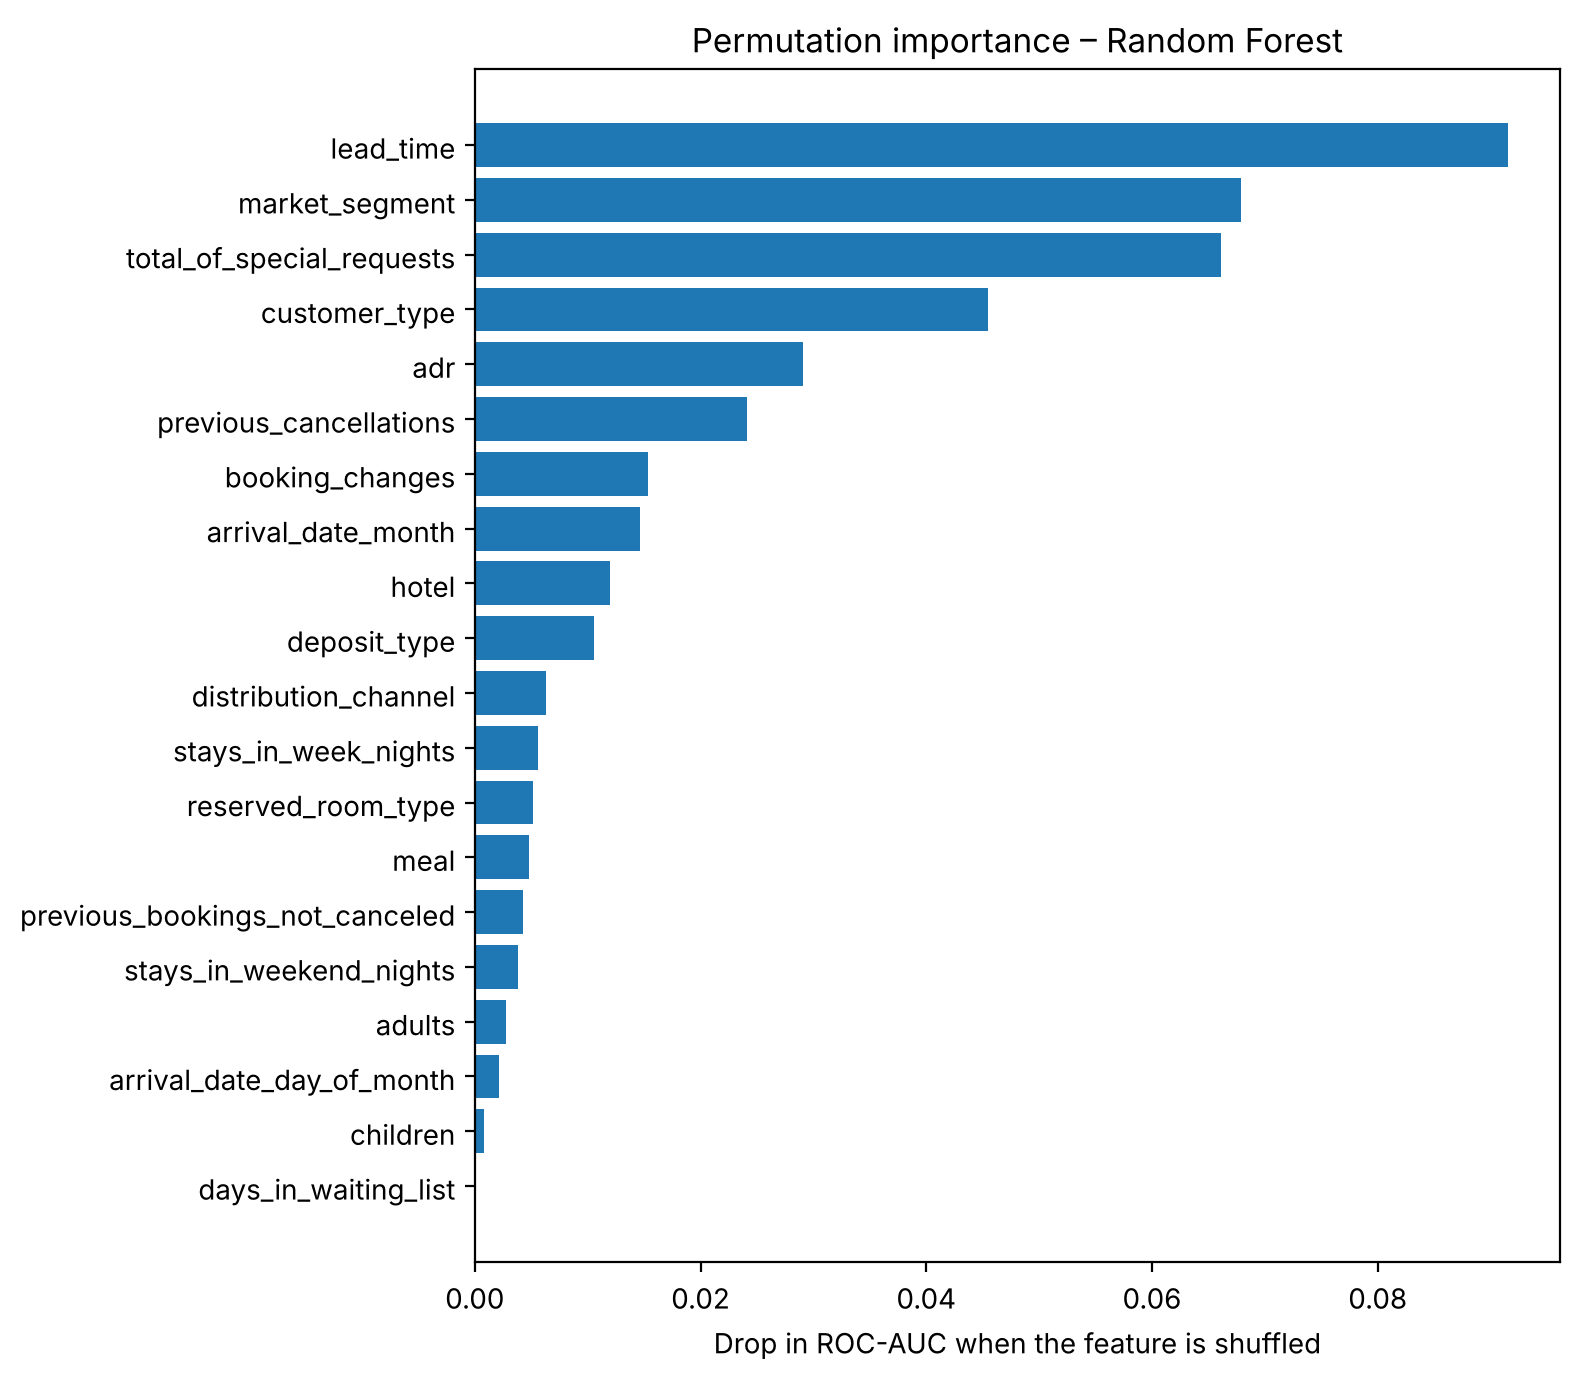

lead_time                    0.0916
market_segment               0.0679
total_of_special_requests    0.0661
customer_type                0.0455
adr                          0.0290
previous_cancellations       0.0241
dtype: float64

In [12]:
best_model = final[best_name]
pi = permutation_importance(best_model, X_test.sample(6000, random_state=SEED), y_test.loc[X_test.sample(6000, random_state=SEED).index],
                            n_repeats=5, random_state=SEED, scoring="roc_auc", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
plt.figure(figsize=(8, 7)); plt.barh(imp.index, imp.values)
plt.xlabel("Drop in ROC-AUC when the feature is shuffled"); plt.title(f"Permutation importance – {best_name}")
plt.tight_layout(); plt.savefig("figures/permutation_importance.png", dpi=200); plt.show()
imp.sort_values(ascending=False).head(6).round(4)

**Lead time** is the strongest predictor (shuffling it lowers ROC-AUC by 0.092), followed by **market segment** (0.068), **number of special requests** (0.066), **customer type** (0.046), **ADR** (0.029) and **previous cancellations** (0.024). This agrees with the exploratory analysis. Permutation importance shows how much the model *relies* on a feature, not that the feature *causes* cancellations, and correlated features share their importance.

## 9. Decision threshold: catching more cancellations
All metrics above use the default threshold 0.5. A hotel that wants to catch more cancellations (e.g. to overbook safely) can lower it – at the price of more false alarms.

In [13]:
proba = best_model.predict_proba(X_test)[:, 1]
rows = []
for t in [0.5, 0.4, 0.3, 0.2]:
    pred = (proba >= t).astype(int)
    rows.append({"threshold": t, "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred), "accuracy": accuracy_score(y_test, pred)})
pd.DataFrame(rows).round(3)

,threshold,precision,recall,F1,accuracy
0,0.5,0.735,0.475,0.577,0.806
1,0.4,0.655,0.593,0.623,0.800
2,0.3,0.563,0.725,0.634,0.766
3,0.2,0.457,0.859,0.597,0.677


## 10. Conclusions
- **Best model:** Random Forest – 80.6 % accuracy, ROC-AUC 0.832, precision 0.735, recall 0.475 – against a majority-class baseline of 72.1 %. Gradient Boosting is practically on par (ROC-AUC 0.826); the tuned Decision Tree (0.797) and KNN (0.775) are weaker.
- **Realistic performance is lower than a naive evaluation suggests.** The first version of this project reported about 81 % accuracy for both models; after removing duplicates and the leaky `assigned_room_type`, the same Decision Tree and KNN reach 0.79 / 0.78 with ROC-AUC 0.79 / 0.77 – only 6–7 percentage points above the majority baseline.
- **What drives cancellations:** long lead times, online travel-agent bookings, no special requests, a previous cancellation, and (rarely) non-refundable deposits (94.8 % of them are cancelled).
- **Threshold matters for a business use:** at 0.5 the Random Forest finds 47.5 % of the cancellations; at 0.3 it finds 72.5 % with a precision of 56.3 % (best F1 = 0.634). The right threshold depends on the cost of an empty room vs. an overbooked one.
- **Limitations:** two Portuguese hotels in 2015–2017; the split is random, not chronological, so performance on future seasons may be lower (a time-based split would be the next step); KNN was tuned on a subsample; the non-refundable-deposit pattern looks like a data artefact rather than a causal effect.
- **Next steps:** time-based validation, probability calibration, a cost-based choice of the threshold, and gradient-boosting tuning with early stopping.